# ML Practical 2

## Mudit Rahangdale
## C-C3-41 

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics 

In [14]:
#step -1 load dataset
df=pd.read_csv("USA_Housing.csv")
df.head() # display first 5 rows

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [15]:
df.tail()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
4995,60567.944140,7.830362,6.137356,3.46,22837.361035,1.060194e+06,USNS Williams\nFPO AP 30153-7653
4996,78491.275435,6.999135,6.576763,4.02,25616.115489,1.482618e+06,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.686886,7.250591,4.805081,2.13,33266.145490,1.030730e+06,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.331235,5.534388,7.130144,5.44,42625.620156,1.198657e+06,USS Wallace\nFPO AE 73316
4999,65510.581804,5.992305,6.792336,4.07,46501.283803,1.298950e+06,"37778 George Ridges Apt. 509\nEast Holly, NV 2..."


In [16]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [17]:
print(df.shape)

(5000, 7)


In [18]:
df.shape

(5000, 7)

In [19]:
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [21]:
df.isnull().sum()

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
#Drop unnecessary columns 
if 'Address' in df.columns:
    df.drop(['Address'],axis=1,inplace=True)

In [24]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05


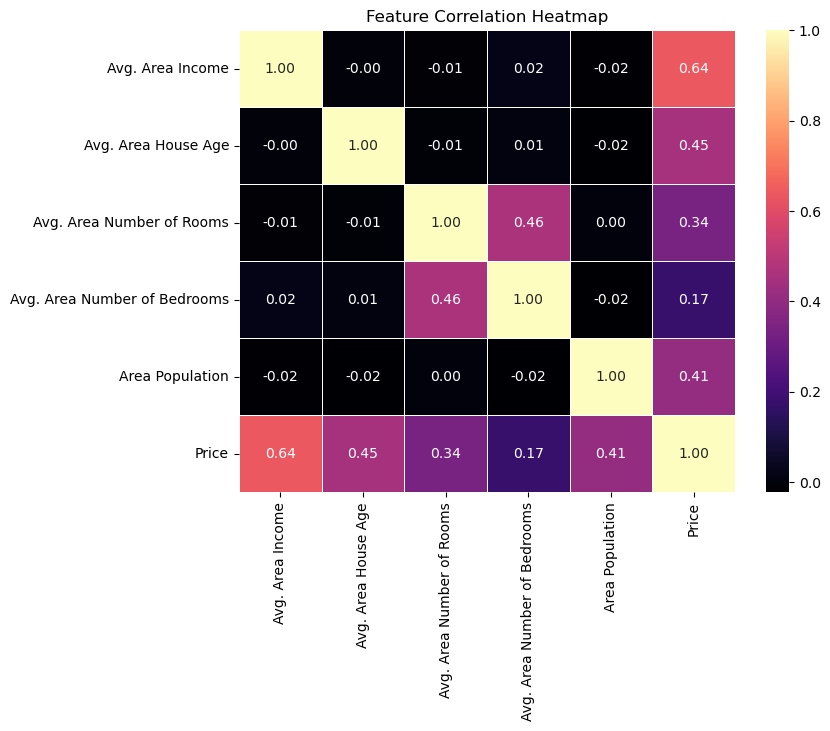

In [25]:
plt.figure(figsize=(8,6))
corr_matrix = df.corr()
sns.heatmap(corr_matrix,cmap='magma',annot=True,fmt=".2f",linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

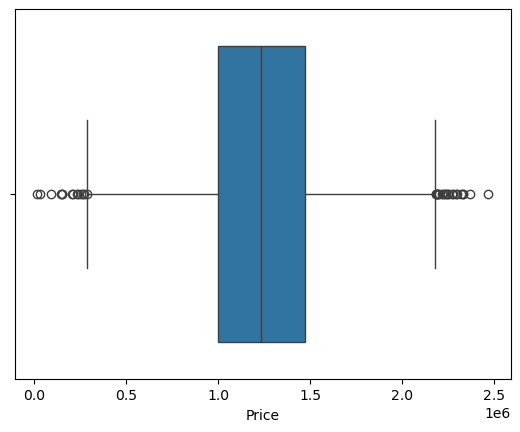

In [26]:
sns.boxplot(x=df["Price"])
plt.show()

<Axes: xlabel='Price', ylabel='count'>

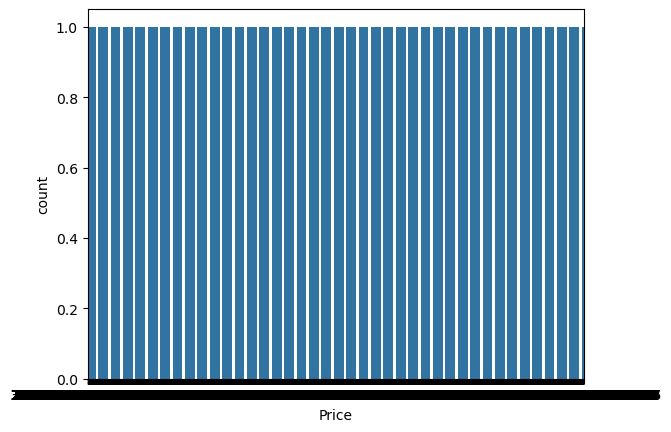

In [27]:
sns.countplot(x="Price" , data=df)

<Axes: xlabel='Avg. Area Number of Rooms', ylabel='count'>

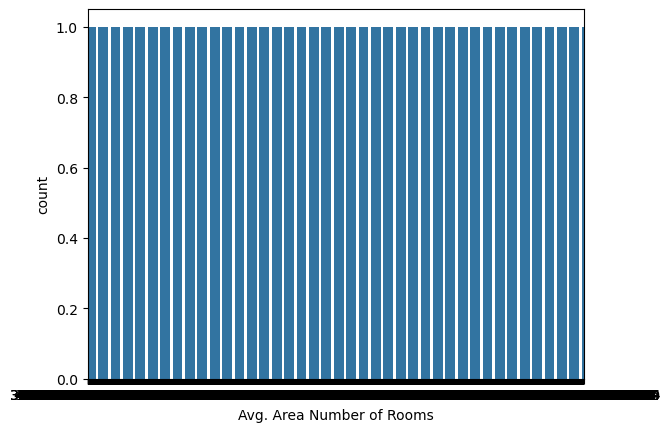

In [28]:
sns.countplot(x="Avg. Area Number of Rooms" , data=df)

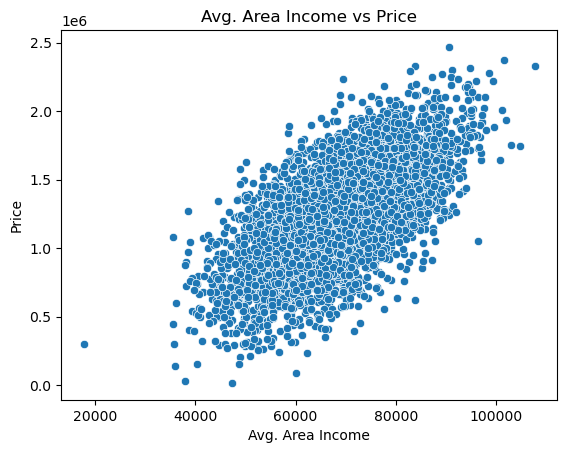

In [29]:
sns.scatterplot(x="Avg. Area Income", y="Price", data =df)

plt.title("Avg. Area Income vs Price")
plt.show()

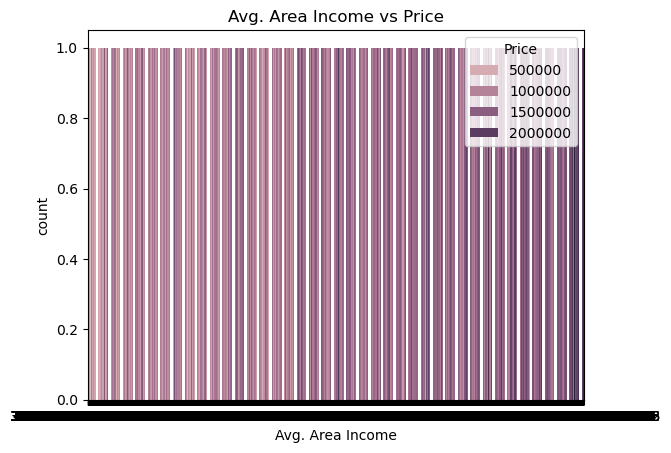

In [30]:
#Bivariate Analysis
sns.countplot(x="Avg. Area Income", hue="Price", data=df)

plt.title("Avg. Area Income vs Price")
plt.show()

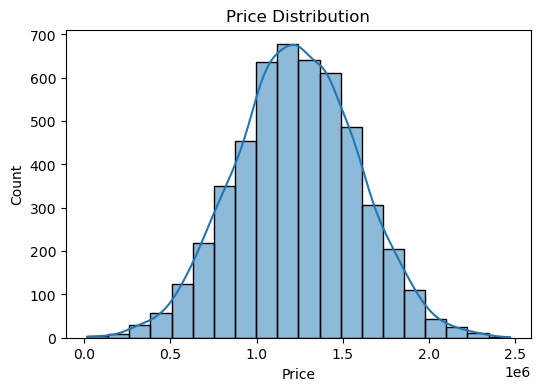

In [31]:
#UNIVARIANT ANALYSIS
plt.figure(figsize=(6,4))
sns.histplot(df["Price"], bins=20, kde=True)

plt.title("Price Distribution")
plt.show()

### SLR

In [32]:
X = df[['Avg. Area Income']]
y = df['Price']

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state =42)

In [53]:
from sklearn.linear_model import LinearRegression
slr_model=LinearRegression ()
slr_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [41]:
y_pred=slr_model.predict(X_test)

In [48]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [52]:
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))
print(r2_score(y_test,y_pred))
 

print(slr_model.intercept_)
print(slr_model.coef_[0])

216826.35309989064
74194887058.66
272387.38417676394
0.39694865192619766
-225053.70287170308
21.208906292657534


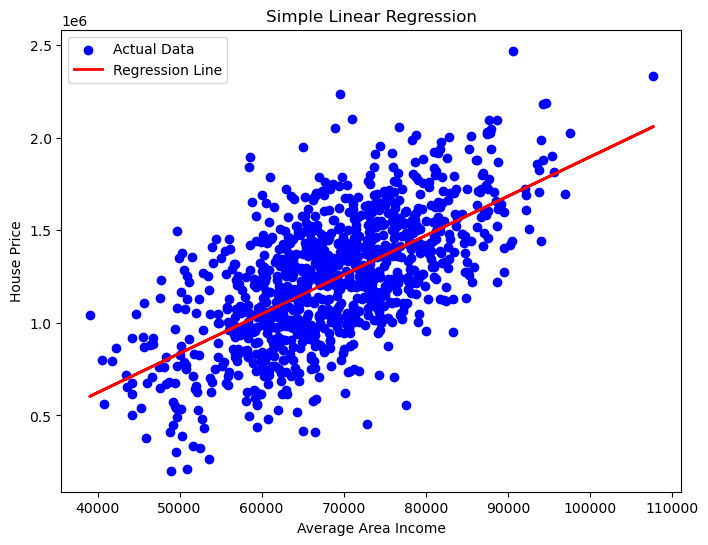

In [46]:
plt. figure(figsize=(8,6))

plt.scatter(X_test, y_test,color='blue', label='Actual Data')

plt.plot(X_test,y_pred,color='red', linewidth=2,label='Regression Line')

plt.xlabel("Average Area Income")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

In [60]:
income = float(input("Enter Average Area Income: "))
new_data = np.array([[income]])
prediction = slr_model.predict(new_data) 

print("Predicted House Price:", prediction[0])

Enter Average Area Income:  68583.108984


Predicted House Price: 1229519.0288290721


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## Hyperarameters Tunning

## Ridge Regression

In [ ]:
from sklearn.model_selection import GridSearchCV

In [61]:
from sklearn.linear_model import Ridge 
ridge=Ridge()
ridge.fit(X_train, y_train)
ridge_pred= ridge.predict(X_test)
print(r2_score(y_test, ridge_pred))


0.3969486519262033


In [62]:
pram_grid={'alpha':[0.001,0.01,1,10,100]}

In [73]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

grid_ridge = GridSearchCV(
    estimator=Ridge(),
    param_grid=pram_grid,
    scoring='r2',
    cv=5
)

In [74]:
grid_ridge.fit(X_test, y_test)

,estimator,Ridge()
,param_grid,"{'alpha': [0.001, 0.01, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,100


In [75]:
print("Best Alpha :", grid_ridge.best_params_)


Best Alpha : {'alpha': 100}


In [76]:
print(grid_ridge.best_score_)

0.38668799290351263
